In [7]:
import numpy as np
import pandas as pd
import datetime as dt
import yfinance as yf
import matplotlib.pyplot as plt
from scipy.stats import norm

In [8]:
years = 15
endDate = dt.datetime.now()
startDate = endDate - dt.timedelta(days = 365*years)

In [9]:
tickers = ['SPY', 'BND', 'GLD', 'QQQ', 'VTI']

In [14]:
adj_close_df = pd.DataFrame()

for ticker in tickers:
    data = yf.download(ticker, start = startDate, end = endDate, auto_adjust=False)
    adj_close_df[ticker] = data['Adj Close']
data.head()

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


Price,Adj Close,Close,High,Low,Open,Volume
Ticker,VTI,VTI,VTI,VTI,VTI,VTI
Date,,,,,,
2011-10-28,50.968498,65.949997,66.059998,65.550003,65.650002,1285900
2011-10-31,49.677849,64.279999,65.250000,64.279999,65.150002,1729900
2011-11-01,48.356304,62.570000,63.279999,62.160000,62.400002,2837000
2011-11-02,49.152325,63.599998,63.779999,62.910000,63.500000,2117800
2011-11-03,50.110661,64.839996,64.930000,63.349998,64.279999,2056700


In [15]:
#Calculate daily log returns and preprocess
log_returns = np.log(adj_close_df / adj_close_df.shift(1))
log_returns = log_returns.dropna()

In [21]:
#assign portfolio
portfolio_value = 1000000
weights = np.array([1/len(tickers)]*len(tickers))

historical_returns = (log_returns * weights).sum(axis = 1)

In [23]:
days = 5
historical_x_days_return = historical_returns.rolling(window = days).sum()

In [28]:
#calculate covariance matrix and SD
cov_matrix = log_returns.cov()*252 # to annualize
portfolio_std_dev = np.sqrt(weights.T @ cov_matrix @ weights)


In [30]:
from scipy.stats import norm
confidence_levels = [0.9,0.95, 0.99]
VaRs = []
for cl in confidence_levels:
    VaR = portfolio_value * portfolio_std_dev * norm.ppf(cl)*np.sqrt(days/252)
    VaRs.append(VaR)

In [38]:
print(f'{"confidence level":<20}{"Value at risk":<20}')
print('-'*40)
for cl, VaR in zip(confidence_levels, VaRs):
    print(f'{cl* 100:>6.0f}%:{"":<8}${VaR:>10,.2f}')

confidence level    Value at risk       
----------------------------------------
    90%:        $ 21,046.58
    95%:        $ 27,013.00
    99%:        $ 38,205.00


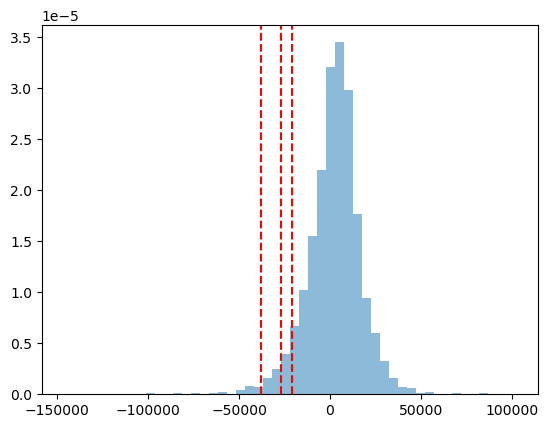

In [41]:
#plot
historical_x_days_return_dollar = historical_x_days_return * portfolio_value
plt.hist(historical_x_days_return_dollar, bins = 50, density = True,alpha =0.5, label = f'{days}-day returns')
for cl, VaR in zip(confidence_levels, VaRs):
    plt.axvline(x = -VaR, linestyle = '--', color = 'r' )
         
plt.show()